In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r'C:\Users\HP\OneDrive\Desktop\KPMG sem3\DA using Python\environmental_data.csv')

In [3]:
df.head(5)

,Observation_ID,Observation_Date,City,Season,Monitoring_Station_Type,Day_Type,Temperature_C,Humidity_Pct,Wind_Speed_kmh,PM2_5_ug_m3,PM10_ug_m3,Noise_Level_dB,AQI
0,ENV0283,2025-01-01,Pune,Monsoon,Residential,Weekday,25.7,92.5,14.8,5.0,22.3,42.5,10
1,ENV1174,2025-01-01,Indore,Summer,Commercial,Weekday,33.0,20.0,10.6,32.5,65.1,58.8,52
2,ENV0472,2025-01-02,Jaipur,Monsoon,Commercial,Weekday,32.7,72.8,17.7,13.8,29.9,63.5,26
3,ENV0587,2025-01-02,Ahmedabad,Summer,Residential,Weekday,36.6,58.3,13.7,7.0,10.0,51.7,39
4,ENV0617,2025-01-02,Indore,Monsoon,Traffic,Weekday,30.2,82.1,13.0,33.3,65.5,63.7,82


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Observation_ID           1200 non-null   object 
 1   Observation_Date         1200 non-null   object 
 2   City                     1200 non-null   object 
 3   Season                   1200 non-null   object 
 4   Monitoring_Station_Type  1200 non-null   object 
 5   Day_Type                 1200 non-null   object 
 6   Temperature_C            1200 non-null   float64
 7   Humidity_Pct             1200 non-null   float64
 8   Wind_Speed_kmh           1200 non-null   float64
 9   PM2_5_ug_m3              1200 non-null   float64
 10  PM10_ug_m3               1200 non-null   float64
 11  Noise_Level_dB           1200 non-null   float64
 12  AQI                      1200 non-null   int64  
dtypes: float64(6), int64(1), object(6)
memory usage: 122.0+ KB


In [6]:
df.isnull().sum()

Observation_ID             0
Observation_Date           0
City                       0
Season                     0
Monitoring_Station_Type    0
Day_Type                   0
Temperature_C              0
Humidity_Pct               0
Wind_Speed_kmh             0
PM2_5_ug_m3                0
PM10_ug_m3                 0
Noise_Level_dB             0
AQI                        0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [4]:
print(df.dtypes)

Observation_ID              object
Observation_Date            object
City                        object
Season                      object
Monitoring_Station_Type     object
Day_Type                    object
Temperature_C              float64
Humidity_Pct               float64
Wind_Speed_kmh             float64
PM2_5_ug_m3                float64
PM10_ug_m3                 float64
Noise_Level_dB             float64
AQI                          int64
dtype: object


In [8]:
# convert observation date into date type 

df["Observation_Date"]= pd.to_datetime(df["Observation_Date"])

# sort the data to prepare for time-based charts 

df = df.sort_values("Observation_Date")

In [12]:
print(df.dtypes)

Observation_ID                     object
Observation_Date           datetime64[ns]
City                               object
Season                             object
Monitoring_Station_Type            object
Day_Type                           object
Temperature_C                     float64
Humidity_Pct                      float64
Wind_Speed_kmh                    float64
PM2_5_ug_m3                       float64
PM10_ug_m3                        float64
Noise_Level_dB                    float64
AQI                                 int64
dtype: object


In [16]:
# display the numberr of unique cities

print(f'\n number of unique cities: {df["City"].nunique()}')

# display the different station types 

print("\n Station types:")
print(df["Monitoring_Station_Type"].unique())

# Display the number of observation 
print(f"Number of unique observations: {df['Observation_ID'].nunique()}")


 number of unique cities: 6

 Station types:
['Residential' 'Commercial' 'Traffic' 'Industrial']
Number of unique observations: 1200


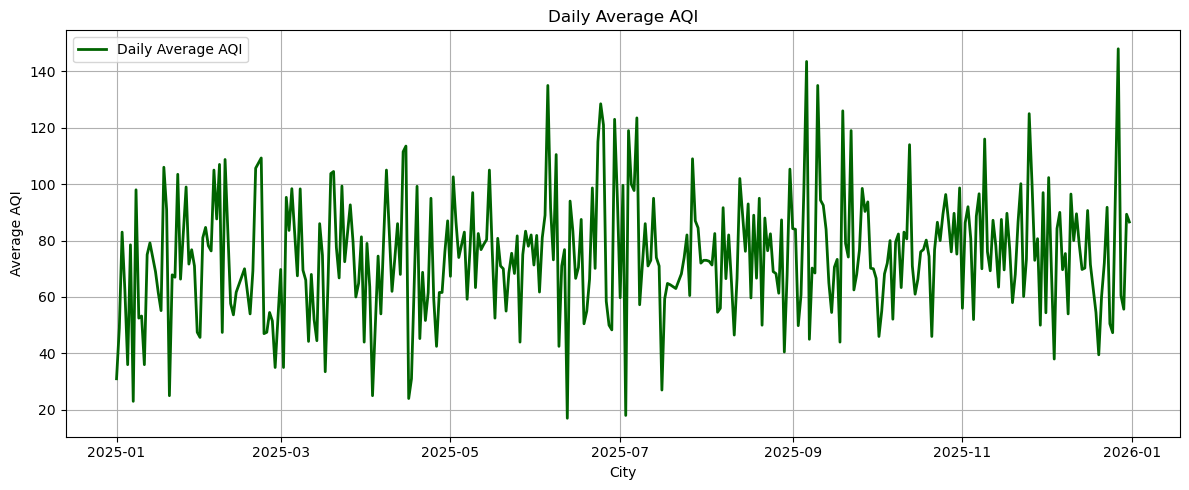

In [ ]:
# Complete the cell like this. Use `daily_aqi.values` for the plotted AQI values:


daily_aqi = df.groupby("Observation_Date")["AQI"].mean()

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    daily_aqi.index,
    daily_aqi.values,
    color="darkgreen",
    linewidth=2,
    label="Daily Average AQI"
)

ax.set(
    title="Daily Average AQI",
    xlabel="City",
    ylabel="Average AQI"
)
# ax.bar_label(bars, fmt="%.1f", padding =3)
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()


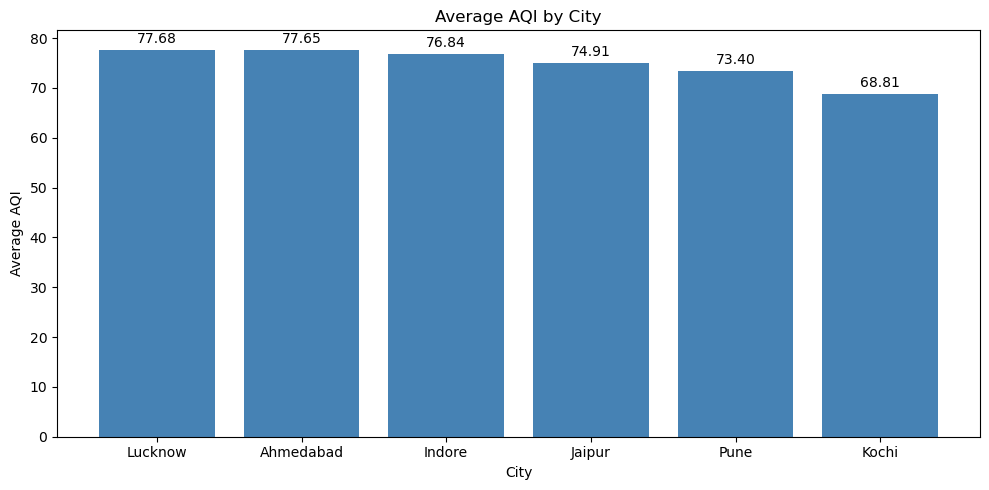

In [26]:
# Group the data by city and calculate the average AQI
city_aqi = df.groupby("City")["AQI"].mean().sort_values(ascending=False)

# Create the figure and axes
fig, ax = plt.subplots(figsize=(10, 5))

# Draw a bar chart using city names and average AQI
bars = ax.bar(
    city_aqi.index,
    city_aqi.values,
    color="steelblue"
)

# Add title and axis labels
ax.set_title("Average AQI by City")
ax.set_xlabel("City")
ax.set_ylabel("Average AQI")

# Add the average AQI value above each bar
ax.bar_label(bars, fmt="%.2f", padding=3)

# Adjust layout and display the chart
plt.tight_layout()
plt.show()

In [34]:
print(df.columns)

Index(['Observation_ID', 'Observation_Date', 'City', 'Season',
       'Monitoring_Station_Type', 'Day_Type', 'Temperature_C', 'Humidity_Pct',
       'Wind_Speed_kmh', 'PM2_5_ug_m3', 'PM10_ug_m3', 'Noise_Level_dB', 'AQI'],
      dtype='object')


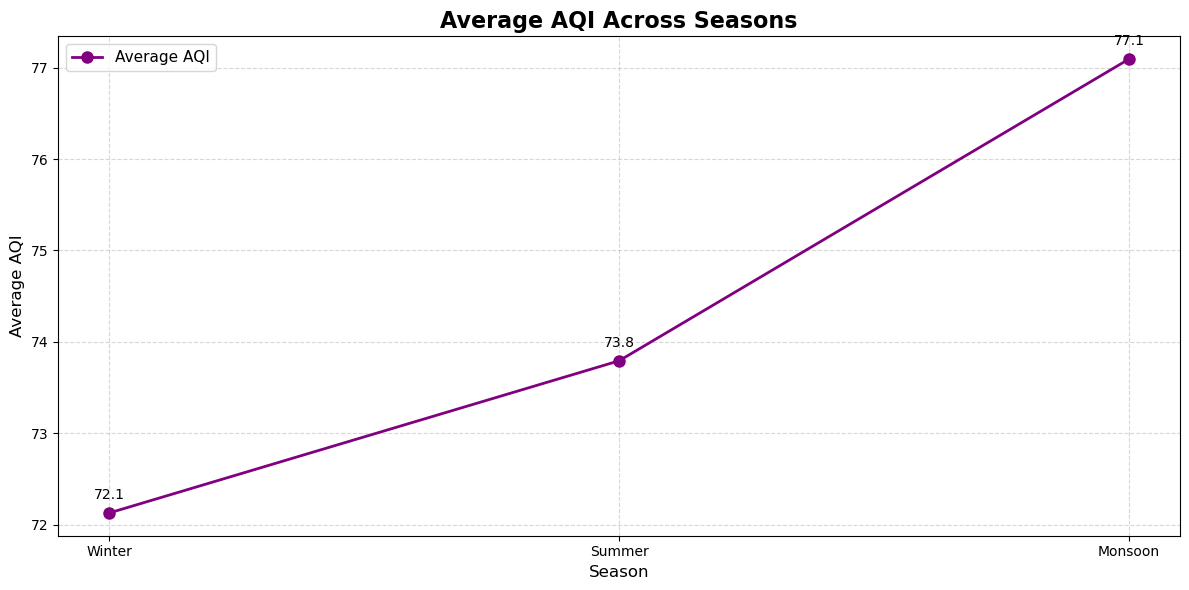

In [40]:
# Calculate average AQI by season
season_aqi = df.groupby("Season")["AQI"].mean()

# Define the order in which seasons should appear
season_order = ["Winter", "Summer", "Monsoon", "Post-Monsoon"]

# Reorder the seasonal averages
season_aqi = season_aqi.reindex(season_order)

# Create a larger figure and axes
fig, ax = plt.subplots(figsize=(12, 6))

# Draw a line chart with markers
ax.plot(
    season_aqi.index,
    season_aqi.values,
    marker="o",
    markersize=8,
    linewidth=2,
    color="purple",
    label="Average AQI"
)

# Set the chart title and axis labels
ax.set_title("Average AQI Across Seasons", fontsize=16, fontweight="bold")
ax.set_xlabel("Season", fontsize=12)
ax.set_ylabel("Average AQI", fontsize=12)

# Customize the font size of tick labels
ax.tick_params(axis="both", labelsize=10)

# Add a legend
ax.legend(fontsize=11)

# Add annotations to show values above the points
for season, value in season_aqi.items():
    ax.annotate(
        f"{value:.1f}",
        xy=(season, value),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        fontsize=10
    )

# Add a light grid to improve readability
ax.grid(True, linestyle="--", alpha=0.5)
# ax.set_ylim(55, 95)

# Adjust layout and display the chart
plt.tight_layout()
plt.show()

In [42]:
print(df.columns.tolist())

['Observation_ID', 'Observation_Date', 'City', 'Season', 'Monitoring_Station_Type', 'Day_Type', 'Temperature_C', 'Humidity_Pct', 'Wind_Speed_kmh', 'PM2_5_ug_m3', 'PM10_ug_m3', 'Noise_Level_dB', 'AQI']


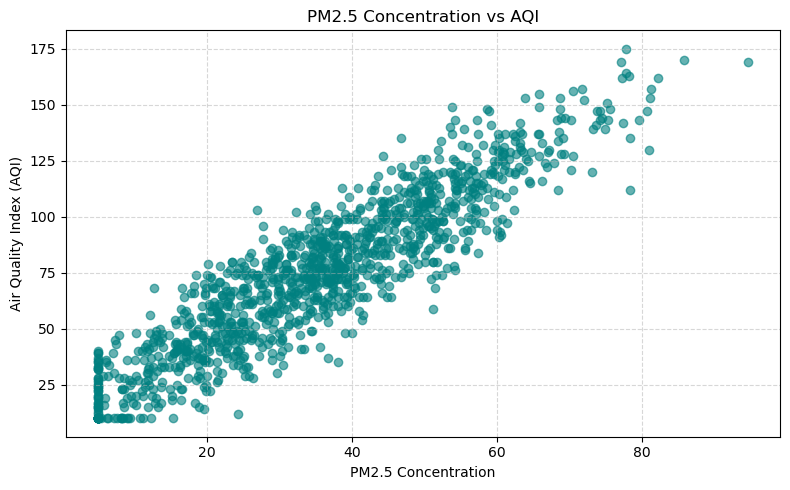

In [43]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(df["PM2_5_ug_m3"], df["AQI"], alpha=0.6, color="teal")
ax.set(
    title="PM2.5 Concentration vs AQI",
    xlabel="PM2.5 Concentration",
    ylabel="Air Quality Index (AQI)"
)
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

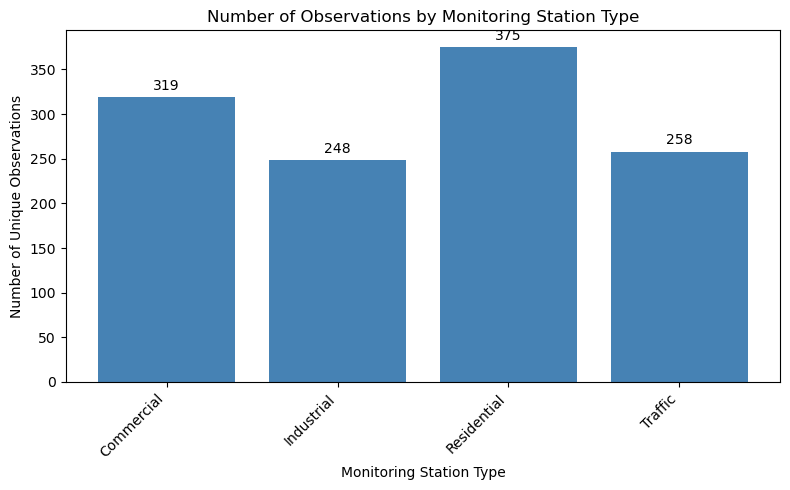

In [44]:
station_counts = df.groupby("Monitoring_Station_Type")["Observation_ID"].nunique()

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(station_counts.index, station_counts.values, color="steelblue")
ax.bar_label(bars, padding=3)
ax.set(
    title="Number of Observations by Monitoring Station Type",
    xlabel="Monitoring Station Type",
    ylabel="Number of Unique Observations"
)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
# create a figure 
plt.figure(figsize=(10,5))

